# PL6 · IA Generativa
## Pré-treino e pós-treino na prática (120 min)

**Mestrado em IA · Prática Laboratorial**

Nesta sessão vai reproduzir, em ponto pequeno, as decisões centrais do pipeline de um LLM:

| Parte | Exercício | Tempo | GPU |
|---|---|---|---|
| A · Pré-treino | 1. Curadoria: filtros heurísticos, deduplicação exata e MinHash-LSH | 25 min | não |
| | 2. Filtro de qualidade com classificador + contas de escala | 15 min | opcional |
| B · Pós-treino | 3. DPO de raiz: log-probabilidades, perda e um passo de gradiente | 20 min | sim |
| | 4. DPO com TRL + LoRA e análise das métricas | 25 min | sim |
| | 5. GRPO com recompensas verificáveis (GSM8K) | 20 min | sim |

**Ambiente recomendado:** Google Colab com GPU T4 (16 GB) — *Ambiente de execução → Alterar tipo → T4 GPU*.

**Convenções**
- `# TODO` assinala código a completar; as células seguintes têm `assert` para verificar a solução.
- ✍️ assinala perguntas a responder por escrito na própria célula (contam para a avaliação).
- Os tempos de treino indicados assumem uma T4; se ficar atrasado, reduza `max_steps`.

## 0 · Preparação (≈ 5 min)

In [1]:
!pip -q install "trl==0.19.1" "transformers==4.51.3" "datasets>=3.0" "datasketch>=1.6" accelerate
!pip -q install --force-reinstall --no-deps "peft==0.15.2"
!pip -q uninstall -y torchao

In [2]:
import os, re, math, random, time, zlib, hashlib, gc
from collections import Counter, defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn.functional as F

SEMENTE = 0
random.seed(SEMENTE); np.random.seed(SEMENTE); torch.manual_seed(SEMENTE)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sem GPU: as Partes 3–5 vão ser muito lentas)")

Dispositivo: cuda Tesla T4


---
# PARTE A · PRÉ-TREINO

## 1 · Curadoria de um corpus web (≈ 25 min)

Vamos usar ~3 000 documentos em português do **FineWeb-2** (`por_Latn`). Como este corpus **já foi filtrado e deduplicado**, vamos **injetar corrupção controlada** para termos verdade de base:

- 50 **duplicados exatos**;
- 100 **quase-duplicados** (palavras apagadas ou trocadas com uma dada taxa);
- 50 documentos **lixo** (menus, hashtags, repetição, *lorem ipsum*).

Assim conseguimos medir *precisão* e *recall* de cada etapa do funil.

In [3]:
from datasets import load_dataset

N_DOCS = 3000

def corpus_sintetico(n=N_DOCS, seed=0):
    """Plano B (sem internet): pseudo-texto com vocabulário português."""
    rng = random.Random(seed)
    vocab = ("o a de que e do da em um para com não uma os no se na por mais as dos como mas foi ao ele das tem "
             "seu sua ou ser quando muito há nos já está também só pelo pela até isso ela entre era depois sem mesmo "
             "cidade governo universidade estudo dados modelo sistema projeto trabalho tempo ano país mundo forma parte "
             "vida história caso problema lugar empresa grupo região investigação resultado processo").split()
    docs = []
    for _ in range(n):
        alvo, frases, w = rng.randint(30, 600), [], 0
        while w < alvo:
            k = rng.randint(6, 20); w += k
            frases.append(" ".join(rng.choice(vocab) for _ in range(k)).capitalize() + ".")
        docs.append(" ".join(frases))
    return docs

def carregar_corpus(n=N_DOCS):
    for nome, cfg in [("HuggingFaceFW/fineweb-2", "por_Latn"), ("HuggingFaceFW/fineweb", "sample-10BT")]:
        try:
            ds = load_dataset(nome, name=cfg, split="train", streaming=True)
            docs = [x["text"] for _, x in zip(range(n), ds)]
            print(f"Carregados {len(docs)} documentos de {nome} [{cfg}]")
            return docs
        except Exception as e:
            print(f"Falhou {nome} [{cfg}]: {type(e).__name__}")
    print("A usar corpus sintético (resultados qualitativamente semelhantes, textos sem sentido).")
    return corpus_sintetico(n)

docs = carregar_corpus()
print("Palavras por documento (mediana):", int(np.median([len(d.split()) for d in docs])))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Resolving data files:   0%|          | 0/66 [00:00<?, ?it/s]

Carregados 3000 documentos de HuggingFaceFW/fineweb-2 [por_Latn]
Palavras por documento (mediana): 268


In [4]:
def quase_duplicado(texto, taxa, rng):
    """Apaga (taxa/2) ou substitui (taxa/2) cada palavra com probabilidade `taxa`."""
    palavras, out = texto.split(), []
    for p in palavras:
        u = rng.random()
        if u < taxa / 2:   continue
        elif u < taxa:     out.append(rng.choice(palavras))
        else:              out.append(p)
    return " ".join(out)

LIXO = [
    lambda rng: "\n".join("• " + rng.choice(["Início", "Contactos", "Loja", "Login", "Carrinho", "Termos", "Privacidade"]) for _ in range(40)),
    lambda rng: " ".join(rng.choice(["#promo", "#oferta", "...", "$$$", "#grátis", "#top"]) for _ in range(200)),
    lambda rng: "clique aqui para saber mais " * 40,
    lambda rng: "Lorem ipsum dolor sit amet, consectetur adipiscing elit. " * 20,
]

def corromper(docs, n_exatos=50, n_quase=100, n_lixo=50, taxa=0.02, seed=0):
    rng = random.Random(seed)
    corpus = [{"id": i, "texto": t, "tipo": "original", "origem": None} for i, t in enumerate(docs)]
    base = [d for d in corpus if len(d["texto"].split()) >= 100]
    for _ in range(n_exatos):
        d = rng.choice(base); corpus.append({"id": len(corpus), "texto": d["texto"], "tipo": "exato", "origem": d["id"]})
    for _ in range(n_quase):
        d = rng.choice(base); corpus.append({"id": len(corpus), "texto": quase_duplicado(d["texto"], taxa, rng), "tipo": "quase", "origem": d["id"]})
    for _ in range(n_lixo):
        corpus.append({"id": len(corpus), "texto": rng.choice(LIXO)(rng), "tipo": "lixo", "origem": None})
    rng.shuffle(corpus)
    return corpus

corpus = corromper(docs)
print(pd.Series([d["tipo"] for d in corpus]).value_counts())

original    3000
quase        100
lixo          50
exato         50
Name: count, dtype: int64


### 1.1 · Filtros heurísticos (estilo Gopher / C4)

Complete as regras em falta. Referência (Rae et al., 2021): 50–100 000 palavras; comprimento médio das palavras entre 3 e 10; rácio símbolos/palavras ≤ 0,1 (contar `#`, `...` e `…`); ≤ 90 % das linhas a começar por marcador; ≤ 30 % das linhas a acabar em reticências; ≥ 80 % das palavras com pelo menos uma letra; pelo menos 2 *stopwords*. E um filtro de repetição: a fração de caracteres ocupada pelo bigrama mais frequente deve ser ≤ 0,20.

In [5]:
STOP = {"de", "a", "o", "que", "e", "do", "da", "em", "um", "para", "é", "com", "não", "uma", "os", "no", "se", "na", "por",
        "the", "be", "to", "of", "and", "that", "have", "with"}

def filtro_gopher(texto, stop=STOP):
    palavras = texto.split()
    n = len(palavras)
    if not (50 <= n <= 100_000):
        return False, "n_palavras"
    if not (3 <= sum(len(p) for p in palavras) / n <= 10):
        return False, "comprimento_palavras"
    if (texto.count("#") + texto.count("...") + texto.count("…")) / n > 0.1:
        return False, "simbolos"
    linhas = [l for l in texto.splitlines() if l.strip()]
    if linhas and sum(bool(re.match(r"^\s*(?:[•\-*#>]|\(?\d+[.)])\s", l)) for l in linhas) / len(linhas) > 0.9:
        return False, "marcadores"
    if linhas and sum(bool(re.search(r"(?:\.\.\.|…)\s*$", l)) for l in linhas) / len(linhas) > 0.3:
        return False, "reticencias"
    if sum(any(ch.isalpha() for ch in p) for p in palavras) / n < 0.8:
        return False, "palavras_alfabeticas"
    if sum(re.sub(r"^\W+|\W+$", "", p.lower()) in stop for p in palavras) < 2:
        return False, "stopwords"
    return True, "ok"

def frac_top_ngrama(texto, n=2):
    p = texto.lower().split()
    grams = [" ".join(p[i:i + n]) for i in range(len(p) - n + 1)]
    if not grams:
        return 0.0
    g, c = Counter(grams).most_common(1)[0]
    return c * len(g.replace(" ", "")) / max(1, sum(len(x) for x in p))

def filtro_repeticao(texto, limiar=0.20):
    if frac_top_ngrama(texto, 2) > limiar:
        return False, "repeticao"
    return True, "ok"

def aplicar_filtros(texto):
    ok, motivo = filtro_gopher(texto)
    if not ok:
        return motivo
    ok, motivo = filtro_repeticao(texto)
    return "ok" if ok else motivo

In [6]:
for d in corpus:
    d["filtro"] = aplicar_filtros(d["texto"])
tab = pd.crosstab(pd.Series([d["tipo"] for d in corpus], name="tipo"), pd.Series([d["filtro"] for d in corpus], name="resultado"))
display(tab)

lixo = [d for d in corpus if d["tipo"] == "lixo"]
assert sum(d["filtro"] != "ok" for d in lixo) == len(lixo), "Todo o lixo injetado devia ser removido pelos filtros."
print("✔ Todo o lixo foi removido.")

resultado,marcadores,ok,repeticao,reticencias,simbolos,stopwords
tipo,,,,,,
exato,0,50,0,0,0,0
lixo,8,0,13,0,18,11
original,0,2999,0,0,1,0
quase,2,96,0,2,0,0


✔ Todo o lixo foi removido.


✍️ **P1.1** Que regras removem cada tipo de lixo? Há documentos *originais* removidos? Mostre 2 exemplos e discuta se são falsos positivos ou lixo real.

**✍️ Resposta:** Os 50 documentos de lixo foram repartidos assim: 8 menus foram apanhados pelos marcadores, 18 pelos símbolos (hashtags, "...", "$$$"), 13 pela repetição ("clique aqui..." repetido) e 11 pelas stopwords (lorem ipsum). Nenhum foi apanhado pelas reticências. No fim foram todos removidos.

Nos documentos originais só houve 1 removido, pela regra dos símbolos. É este:

`[simbolos] Muito bem…apos longo tempo de ausencia… Arranjei uma casinha nova…. Ja a tenho a algum tempo… Mas ainda esta a meio gás…`

Só apareceu um exemplo, por isso não consigo mostrar dois. Parece mais lixo real (muitos "...", texto informal e pouco estruturado) do que um falso positivo, mas podia ser um post válido. O corpus usado foi o FineWeb-2 real, não o sintético.

In [7]:
for d in [d for d in corpus if d["tipo"] == "original" and d["filtro"] != "ok"][:2]:
    print(f'[{d["filtro"]}]', d["texto"][:300].replace("\n", " ⏎ "), "\n")

[simbolos] Muito bem…apos longo tempo de ausencia… ⏎ Arranjei uma casinha nova…. ⏎ Ja a tenho a algum tempo… Mas ainda esta a meio gás… ⏎ Se por acaso alguma alma quiser la ir dar um salto é so ir a ⏎ e ja agora ⏎ Se querem um blog virado pa informatica…têm aqui o blog do “meu patrão” ⏎ Que como “bom patrao” que é…anda me 



### 1.2 · Deduplicação exata

Normalize o texto (minúsculas, espaços colapsados), calcule um hash e mantenha, em cada grupo, o documento com **menor `id`** (o original).

In [8]:
def normalizar(texto):
    return re.sub(r"\s+", " ", texto.lower()).strip()

def dedup_exata(docs_):
    grupos = defaultdict(list)
    for d in docs_:
        grupos[hashlib.md5(normalizar(d["texto"]).encode()).hexdigest()].append(d)
    manter = {min(g, key=lambda d: d["id"])["id"] for g in grupos.values()}
    return [d for d in docs_ if d["id"] in manter], [d for d in docs_ if d["id"] not in manter]

apos_filtros = [d for d in corpus if d["filtro"] == "ok"]
apos_exata, removidos = dedup_exata(apos_filtros)
print(f"{len(apos_filtros)} → {len(apos_exata)} documentos;", Counter(d["tipo"] for d in removidos))
assert Counter(d["tipo"] for d in removidos)["exato"] == 50

3145 → 3094 documentos; Counter({'exato': 50, 'quase': 1})


### 1.3 · MinHash de raiz

Para dois conjuntos de *shingles* (5-gramas de palavras) $A$ e $B$:

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|},\qquad P\big[\min h(A)=\min h(B)\big]=J(A,B)$$

Implemente a assinatura com $k$ funções de hash universais $h_j(x)=(a_j x+b_j) \bmod p$ e verifique que a fração de posições iguais estima $J$.

In [9]:
def shingles(texto, n=5):
    p = re.findall(r"\w+", texto.lower())
    return {" ".join(p[i:i + n]) for i in range(max(1, len(p) - n + 1))}

def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

P_PRIMO = np.uint64(4294967311)  # primo > 2^32
def assinatura_minhash(sh, k=112, seed=1):
    rng = np.random.default_rng(seed)               # a mesma semente para todos os documentos!
    a = rng.integers(1, 2**31, size=k, dtype=np.uint64)
    b = rng.integers(0, 2**31, size=k, dtype=np.uint64)
    x = np.fromiter((zlib.crc32(s.encode()) for s in sh), dtype=np.uint64, count=len(sh))
    h = (a[:, None] * x[None, :] + b[:, None]) % P_PRIMO
    return h.min(axis=1)

def jaccard_estimado(s1, s2):
    return float(np.mean(s1 == s2))

In [10]:
rng = random.Random(1)
base = [d["texto"] for d in apos_exata if len(d["texto"].split()) >= 150]
linhas = []
for taxa in [0.01, 0.03, 0.05, 0.10, 0.20]:
    for _ in range(5):
        a = rng.choice(base); b = quase_duplicado(a, taxa, rng)
        sa, sb = shingles(a), shingles(b)
        for k in [16, 112, 512]:
            linhas.append({"taxa": taxa, "k": k, "J_exato": jaccard(sa, sb),
                           "J_estimado": jaccard_estimado(assinatura_minhash(sa, k), assinatura_minhash(sb, k))})
res = pd.DataFrame(linhas); res["erro_abs"] = (res.J_estimado - res.J_exato).abs()
display(res.groupby("k").erro_abs.mean().rename("erro absoluto médio"))
assert res[res.k == 512].erro_abs.mean() < 0.05

,erro absoluto médio
k,
16,0.067333
112,0.022712
512,0.011285


✍️ **P1.2** Como varia o erro com $k$? Relacione com o desvio-padrão do estimador, $\sqrt{J(1-J)/k}$. Porque é que 5 % de palavras alteradas dão um $J$ tão baixo?

**✍️ Resposta:** O erro baixa quando aumentamos o k, mais ou menos como 1/raiz(k). Medi um erro médio de 0,067 com k=16, 0,023 com k=112 e 0,011 com k=512, que segue a mesma tendência do desvio-padrão sqrt(J(1-J)/k). Por isso k=112 já é uma boa escolha e aumentar muito mais é gastar tempo sem grande ganho.

Com 5% de palavras alteradas o J desce para cerca de 0,66. Isto acontece porque cada shingle tem 5 palavras e basta uma delas ser apagada ou trocada para o shingle deixar de ser igual. Em teoria seria (1-0,05)^5 ≈ 0,77, mas na prática é ainda pior porque apagar palavras também muda os shingles todos à volta.

### 1.4 · LSH por bandas e curva em S

Divida a assinatura em $b$ bandas de $r$ linhas: dois documentos são **candidatos** se coincidirem em **todas** as linhas de **pelo menos uma** banda. Teoricamente:

$$P(\text{candidato}\mid s)=1-(1-s^{r})^{b}$$

O FineWeb usa $b=14$, $r=8$ ($k=112$).

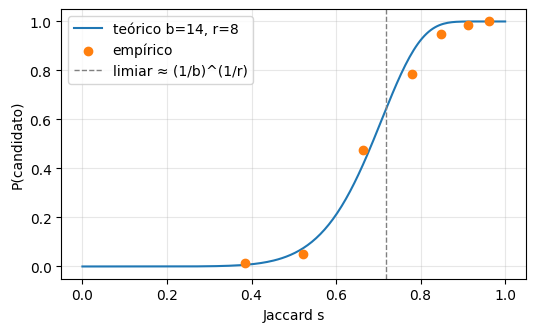

In [11]:
def candidato_lsh(s1, s2, b=14, r=8):
    assert len(s1) == b * r
    return any(np.array_equal(s1[i * r:(i + 1) * r], s2[i * r:(i + 1) * r]) for i in range(b))

def p_teorico(s, b=14, r=8):
    return 1 - (1 - s ** r) ** b

rng = random.Random(2)
pontos = []
for taxa in [0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12]:
    Js, det = [], 0
    for _ in range(80):
        a = rng.choice(base); bq = quase_duplicado(a, taxa, rng)
        sa, sb = shingles(a), shingles(bq)
        Js.append(jaccard(sa, sb)); det += candidato_lsh(assinatura_minhash(sa), assinatura_minhash(sb))
    pontos.append((np.mean(Js), det / 80))

s = np.linspace(0, 1, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(s, p_teorico(s), label="teórico b=14, r=8")
plt.scatter(*zip(*pontos), color="C1", zorder=3, label="empírico")
plt.axvline((1 / 14) ** (1 / 8), ls="--", c="gray", lw=1, label="limiar ≈ (1/b)^(1/r)")
plt.xlabel("Jaccard s"); plt.ylabel("P(candidato)"); plt.legend(); plt.grid(alpha=.3); plt.show()

✍️ **P1.3** Os pontos empíricos seguem a curva? A partir de que taxa de edição os quase-duplicados deixam de ser apanhados? Que $(b,r)$ escolheria para apanhar $s\ge 0{,}6$ com o mesmo $k=112$?

**✍️ Resposta:** Sim, os pontos seguem mais ou menos a curva em S, embora fiquem um pouco abaixo da curva teórica para J mais alto. Com 1% de edições J≈0,94 e são apanhados quase todos (P≈0,99). Com 3% J≈0,80 e P≈0,78. Com 5% J≈0,66 e P cai para cerca de 0,47. Com 8% J≈0,53 e quase nenhum é apanhado (P≈0,05), e com 12% J≈0,39 e P≈0,01.

Ou seja, o limiar de (14,8) é cerca de 0,72 e a deteção cai sobretudo entre os 5% e os 8% de palavras alteradas.

Se quisesse apanhar s≥0,6 com k=112 usava b=28 e r=4. O limiar passa para cerca de 0,40 e a probabilidade de apanhar um documento com s=0,6 fica perto de 98%.

### 1.5 · Deduplicação à escala do corpus (datasketch)

In [12]:
from datasketch import MinHash, MinHashLSH

def minhash_ds(sh, k=112):
    m = MinHash(num_perm=k, seed=1)
    m.update_batch([s.encode("utf8") for s in sh])
    return m

def dedup_quase(docs_, b=14, r=8):
    lsh, mhs = MinHashLSH(num_perm=b * r, params=(b, r)), {}
    for d in docs_:
        mhs[d["id"]] = minhash_ds(shingles(d["texto"]), b * r); lsh.insert(d["id"], mhs[d["id"]])
    pai = {d["id"]: d["id"] for d in docs_}
    def raiz(x):
        while pai[x] != x:
            pai[x] = pai[pai[x]]; x = pai[x]
        return x
    for d in docs_:
        for c in lsh.query(mhs[d["id"]]):
            ra, rb = raiz(d["id"]), raiz(c)
            if ra != rb: pai[max(ra, rb)] = min(ra, rb)   # o representante é o menor id
    grupo = {d["id"]: raiz(d["id"]) for d in docs_}
    return [d for d in docs_ if grupo[d["id"]] == d["id"]], grupo

t0 = time.time()
final, grupo = dedup_quase(apos_exata)
quase = [d for d in apos_exata if d["tipo"] == "quase"]
recall = np.mean([grupo[d["id"]] != d["id"] for d in quase])
orig_rem = [d for d in apos_exata if d["tipo"] == "original" and grupo[d["id"]] != d["id"]]
print(f"{len(apos_exata)} → {len(final)} documentos em {time.time() - t0:.0f}s")
print(f"Recall nos quase-duplicados injetados: {recall:.1%}  |  originais removidos: {len(orig_rem)}")

3094 → 3005 documentos em 5s
Recall nos quase-duplicados injetados: 93.7%  |  originais removidos: 0


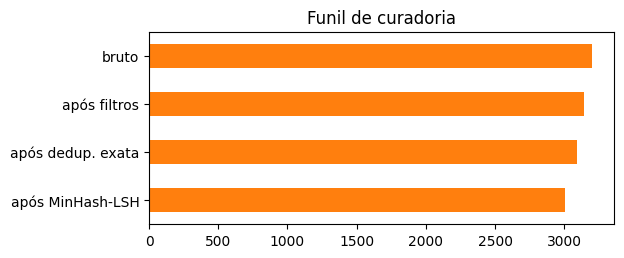

In [13]:
# Funil completo
funil = pd.Series({"bruto": len(corpus), "após filtros": len(apos_filtros), "após dedup. exata": len(apos_exata), "após MinHash-LSH": len(final)})
funil.plot.barh(figsize=(6, 2.5), color="C1"); plt.gca().invert_yaxis(); plt.title("Funil de curadoria"); plt.show()
for d in orig_rem[:2]:
    rep = next(x for x in apos_exata if x["id"] == grupo[d["id"]])
    print(f'J = {jaccard(shingles(d["texto"]), shingles(rep["texto"])):.2f}\n  A: {d["texto"][:160]!r}\n  B: {rep["texto"][:160]!r}\n')

✍️ **P1.4** Os originais removidos pelo MinHash são erros ou duplicados *naturais* do corpus? O que mudaria se a deduplicação fosse global sobre vários *snapshots* do Common Crawl (recorde o resultado do FineWeb)?

**✍️ Resposta:** Nesta execução não houve nenhum original removido pelo MinHash (originais removidos: 0). O que aconteceu foi 3094 → 3005 documentos e um recall de 93,7% nos quase-duplicados injetados. Por isso a pergunta não se aplica muito: os removidos são quase todos os quase-duplicados que foram injetados de propósito, e não originais.

Se aparecessem originais, seriam duplicados naturais, ou seja, documentos com o mesmo template ou boilerplate e não erros do algoritmo. Numa deduplicação global sobre vários snapshots do Common Crawl o efeito era muito maior, porque grande parte do texto repetido só aparece entre snapshots. O FineWeb mostra que isso remove uma parte enorme do corpus e ajuda a evitar memorização e contaminação dos benchmarks, mas também pode apagar versões válidas e atualizadas das páginas.

## 2 · Filtro de qualidade e contas de escala (≈ 15 min)

### 2.1 · Classificador educativo do FineWeb-Edu

O `HuggingFaceFW/fineweb-edu-classifier` é um regressor (embeddings Snowflake-Arctic + cabeça linear) treinado com ~450 mil notas 0–5 atribuídas pelo Llama-3-70B. O FineWeb-Edu mantém os documentos com nota arredondada ≥ 3.

Resolving data files:   0%|          | 0/27468 [00:00<?, ?it/s]

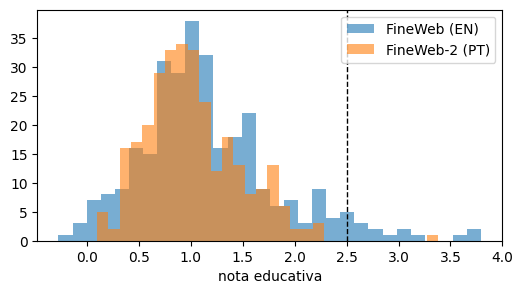

Fração com nota ≥ 3 — EN: 4.7% | PT: 0.3%

[3.69] Was The Race To The Moon Real?; June 1994; Scientific American Magazine; by Logsdon, Dupas; 8 Page(s) Twenty-five years ago, on July 20, 1969, Neil A. Armstrong took the first footsteps on the surface of the moon. That event marked a political and te

[3.80] Imagine a human spacecraft crew voyaging through space. A satellite sends a warning; energetic particles are being accelerated from the sun's corona, sending dangerous radiation toward their spacecraft, but the crew isn't worried. Long before their j

[-0.27] Short Dressesfrom £39 FURTHER REDUCTIONSShop All Sale Jackets & Coatsfrom £35 Our New In pieces are perfect to keep your wardrobe refreshed. Find a look you love in our latest lookbooks. Join the party on social media and get the lowdown on all thing

[-0.05] Her warm-weather faves, with a glittery new look she'll flip for! - Soft rubber footbeds are coated with sugar glitter - Flexible transparent plastic straps are infused wi

In [14]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
CLS = "HuggingFaceFW/fineweb-edu-classifier"
tok_c = AutoTokenizer.from_pretrained(CLS)
clf = AutoModelForSequenceClassification.from_pretrained(CLS).to(DEVICE).eval()

@torch.no_grad()
def nota_edu(textos, bs=16):
    notas = []
    for i in range(0, len(textos), bs):
        enc = tok_c(textos[i:i + bs], return_tensors="pt", padding="longest", truncation=True, max_length=512).to(DEVICE)
        notas += clf(**enc).logits.squeeze(-1).float().cpu().tolist()
    return np.array(notas)

en = load_dataset("HuggingFaceFW/fineweb", name="sample-10BT", split="train", streaming=True)
docs_en = [x["text"] for _, x in zip(range(300), en)]
notas_en = nota_edu(docs_en)
notas_pt = nota_edu([d["texto"] for d in final[:300]])

plt.figure(figsize=(6, 3)); plt.hist(notas_en, bins=30, alpha=.6, label="FineWeb (EN)"); plt.hist(notas_pt, bins=30, alpha=.6, label="FineWeb-2 (PT)")
plt.axvline(2.5, c="k", ls="--", lw=1); plt.legend(); plt.xlabel("nota educativa"); plt.show()
print(f"Fração com nota ≥ 3 — EN: {(notas_en >= 2.5).mean():.1%} | PT: {(notas_pt >= 2.5).mean():.1%}")
for i in list(np.argsort(notas_en)[-2:]) + list(np.argsort(notas_en)[:2]):
    print(f"\n[{notas_en[i]:.2f}]", docs_en[i][:250].replace("\n", " "))

✍️ **P2.1** Que fração passa o limiar? Que características têm os documentos com nota alta e baixa? O que acontece com os documentos em português e que viés isso introduziria num corpus multilingue?

**✍️ Resposta:** No histograma passaram 4,7% dos documentos em inglês e só 0,3% dos documentos em português. Isto faz sentido porque o classificador foi treinado com notas dadas pelo Llama-3-70B a texto inglês, por isso dá notas mais baixas a texto noutras línguas.

Os documentos com nota alta são texto explicativo, como os exemplos com 3,69 e 3,80 sobre a chegada à Lua e viagens espaciais. Os de nota baixa são anúncios e lojas, como os exemplos com -0,27 e -0,05 sobre roupa e sapatos. Em português o classificador dá notas mais baixas mesmo a bons textos, o que num corpus multilingue acaba por prejudicar o português e favorecer o inglês. Para corrigir isto usava limiares diferentes por língua ou um classificador multilingue.

### 2.2 · Calculadora de pré-treino

Implemente as funções e responda às perguntas. Use o pico denso BF16 da H100 (989 TFLOP/s).

In [15]:
def flops_treino(N, D):
    return 6 * N * D

def dias_treino(N, D, n_gpus, pico=989e12, mfu=0.40):
    return flops_treino(N, D) / (n_gpus * pico * mfu) / 86400

def memoria_estados_gb(psi, nd=1, estagio=0, K=12):
    """Pesos+gradientes BF16 (2+2 bytes) + estados Adam (K=12 bytes), com ZeRO-0/1/2/3."""
    if estagio >= 3:
        return psi * (4 + K) / nd / 1e9
    grads = 2 / nd if estagio >= 2 else 2
    estados = K / nd if estagio >= 1 else K
    return psi * (2 + grads + estados) / 1e9

assert abs(flops_treino(405e9, 15.6e12) / 3.8e25 - 1) < 0.02
assert abs(dias_treino(70e9, 15e12, 2048) - 90) < 2
assert memoria_estados_gb(70e9, 64, 3) == 17.5
print("✔ Calculadora correta")

✔ Calculadora correta


In [16]:
# Q-a) Quantas H100 para treinar um 8B com 15T tokens em 30 dias com MFU de 40%?
n_gpus = math.ceil(flops_treino(8e9, 15e12) / (989e12 * 0.40 * 30 * 86400))
print("GPUs necessárias:", n_gpus)

# Q-b) Afinação completa com Adam numa T4 (16 GB): cabe um 0,5B? E um 7B?
for psi in [0.5e9, 7e9]:
    print(f"{psi/1e9:.1f}B → {memoria_estados_gb(psi):.0f} GB só em estados (sem ativações)")

GPUs necessárias: 703
0.5B → 8 GB só em estados (sem ativações)
7.0B → 112 GB só em estados (sem ativações)


✍️ **P2.2** Interprete os resultados de (a) e (b). Porque é que, nas Partes 4–5, usamos LoRA mesmo num modelo de 0,5B?

**✍️ Resposta:** (a) Os FLOPs são 6*N*D = 6 * 8e9 * 15e12 = 7,2e23. Cada H100 com 40% de MFU faz 989e12*0,4 = 3,956e14 FLOP/s, o que em 30 dias dá cerca de 1,03e21 FLOPs. Dividindo dá cerca de 703, por isso são precisas 703 H100.

(b) Só os estados do Adam precisam de 16 bytes por parâmetro, então um modelo de 0,5B precisa de 8 GB e um de 7B precisa de 112 GB. Na T4 de 16 GB o 0,5B já não cabe bem com ativações, e no DPO ainda é preciso ter a política e a referência. Por isso usamos LoRA: treina só uma parte pequena dos parâmetros, poupa muita memória do otimizador e deixa-nos ter o mesmo modelo base para as duas cópias.

---
# PARTE B · PÓS-TREINO

## 3 · DPO de raiz (≈ 20 min)

$$\mathcal{L}_{\text{DPO}}=-\log\sigma\!\Big(\beta\log\frac{\pi_\theta(y_w|x)}{\pi_{\text{ref}}(y_w|x)}-\beta\log\frac{\pi_\theta(y_l|x)}{\pi_{\text{ref}}(y_l|x)}\Big)$$

Usamos `Qwen/Qwen2.5-0.5B-Instruct` como política e como referência.

In [17]:
from transformers import AutoTokenizer, AutoModelForCausalLM
MODELO = "Qwen/Qwen2.5-0.5B-Instruct"
BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
tok = AutoTokenizer.from_pretrained(MODELO)
politica = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.float32).to(DEVICE)
referencia = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.float32).to(DEVICE).eval()
for p in referencia.parameters(): p.requires_grad_(False)
print(f"{sum(p.numel() for p in politica.parameters())/1e6:.0f}M parâmetros")

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


494M parâmetros


### 3.1 · Log-probabilidade de uma resposta

$\log\pi(y|x)=\sum_t \log\pi(y_t\mid x,y_{<t})$ — **só nos tokens da resposta** (incluindo o fim de turno). Atenção ao desvio de uma posição entre *logits* e alvos.

In [18]:
def logprob_resposta(modelo, prompt, resposta, grad=False):
    txt_p = tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    ids_p = tok(txt_p, add_special_tokens=False, return_tensors="pt").input_ids
    ids_r = tok(resposta + tok.eos_token, add_special_tokens=False, return_tensors="pt").input_ids
    ids = torch.cat([ids_p, ids_r], dim=1).to(modelo.device)
    with torch.set_grad_enabled(grad):
        logits = modelo(ids).logits[:, :-1].float()          # logits[t] prevê ids[t+1]
        alvo = ids[:, 1:]
        lp = torch.log_softmax(logits, -1).gather(-1, alvo.unsqueeze(-1)).squeeze(-1)
        mask = torch.arange(ids.shape[1] - 1, device=alvo.device) >= (ids_p.shape[1] - 1)
        return (lp * mask).sum()

### 3.2 · A perda

In [19]:
def perda_dpo(lp_pol_w, lp_pol_l, lp_ref_w, lp_ref_l, beta=0.1):
    """Devolve (perda, recompensa implícita de y_w, recompensa implícita de y_l)."""
    rw = beta * (lp_pol_w - lp_ref_w)
    rl = beta * (lp_pol_l - lp_ref_l)
    return -F.logsigmoid(rw - rl), rw, rl

# Verificação com o Exercício II da aula teórica: diferenças +2 e −1, β = 0,1  →  perda ≈ 0,554
L, rw, rl = perda_dpo(torch.tensor(2.), torch.tensor(-1.), torch.tensor(0.), torch.tensor(0.))
assert abs(L.item() - 0.5544) < 1e-3
print(f"perda = {L.item():.4f}   peso do gradiente σ(r_l − r_w) = {torch.sigmoid(rl - rw).item():.3f}")

perda = 0.5544   peso do gradiente σ(r_l − r_w) = 0.426


In [20]:
PROMPT = "Explica em duas frases o que é a deduplicação de dados no pré-treino de LLMs."
Y_W = ("É a remoção de documentos repetidos ou quase repetidos do corpus de treino. Evita que o modelo memorize "
       "texto duplicado e poupa compute, além de reduzir a contaminação de benchmarks.")
Y_L = "Deduplicação é quando os dados são duplicados para o modelo aprender melhor."

lp = {nome: logprob_resposta(m, PROMPT, y).item() for nome, m, y in
      [("pol_w", politica, Y_W), ("pol_l", politica, Y_L), ("ref_w", referencia, Y_W), ("ref_l", referencia, Y_L)]}
L0, _, _ = perda_dpo(torch.tensor(lp["pol_w"]), torch.tensor(lp["pol_l"]), torch.tensor(lp["ref_w"]), torch.tensor(lp["ref_l"]))
print(lp); print(f"perda inicial = {L0.item():.4f}   (log 2 = {math.log(2):.4f})")

{'pol_w': -137.22608947753906, 'pol_l': -64.95848083496094, 'ref_w': -137.22608947753906, 'ref_l': -64.95848083496094}
perda inicial = 0.6931   (log 2 = 0.6931)


✍️ **P3.1** Porque é que a perda inicial é exatamente $\log 2$? Qual das duas respostas tem maior $\log\pi$ e porque é que isso **não** significa que o modelo a prefira?

**✍️ Resposta:** No início a política é igual à referência, por isso log π é igual nos dois e as recompensas implícitas são 0. A margem é 0 e a perda fica -log σ(0) = -log 0,5 = log 2 ≈ 0,693, que foi o valor que deu (0,6931).

Nesta execução o log π foi -137,2 para a chosen e -65,0 para a rejected, por isso é a resposta rejeitada que tem maior log π, porque é mais curta. O log π é uma soma de log-probabilidades e todas são negativas, por isso quanto menos tokens tiver a resposta, menos negativo é o total. Mas isso não quer dizer que o modelo a prefira, porque o log π absoluto depende do comprimento e da tokenização. O DPO só olha para a diferença entre política e referência, que no início é zero para as duas.

### 3.3 · Dez passos de gradiente num único par

Implemente o ciclo de treino (SGD, `lr=1e-5`) e registe $\log\pi_\theta(y_w)$, $\log\pi_\theta(y_l)$ e a margem.

,passo,perda,logp_w,logp_l,margem
0,0,0.693,-137.226,-64.958,0.000
1,1,0.325,-131.436,-68.748,0.958
2,2,0.210,-128.590,-70.839,1.452
3,3,0.156,-126.746,-72.281,1.780
4,4,0.124,-125.391,-73.385,2.026
5,5,0.103,-124.322,-74.282,2.223
6,6,0.088,-123.441,-75.038,2.386
7,7,0.077,-122.692,-75.692,2.527
8,8,0.068,-122.041,-76.269,2.650
9,9,0.061,-121.466,-76.786,2.759


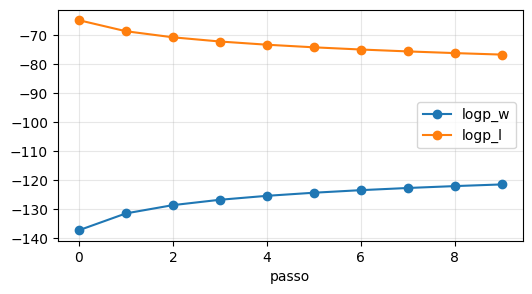

In [21]:
otim = torch.optim.SGD(politica.parameters(), lr=1e-5)
hist = []
for passo in range(10):
    otim.zero_grad()
    lw = logprob_resposta(politica, PROMPT, Y_W, grad=True)
    ll = logprob_resposta(politica, PROMPT, Y_L, grad=True)
    perda, rw, rl = perda_dpo(lw, ll, torch.tensor(lp["ref_w"]), torch.tensor(lp["ref_l"]))
    perda.backward()
    otim.step()
    hist.append({"passo": passo, "perda": perda.item(), "logp_w": lw.item(), "logp_l": ll.item(), "margem": (rw - rl).item()})
h = pd.DataFrame(hist); display(h.round(3))
h.plot(x="passo", y=["logp_w", "logp_l"], figsize=(6, 3), marker="o"); plt.grid(alpha=.3); plt.show()

✍️ **P3.2** A margem cresce? O que acontece a $\log\pi_\theta(y_w)$ — sobe, desce ou fica? Relacione com o *deslocamento de verosimilhança* (Razin et al., 2024). Que papel tem $\beta$?

**✍️ Resposta:** Sim, a margem cresce ao longo dos passos, de 0 até cerca de 2,76 ao passo 9. Nesta execução o log π da resposta escolhida também subiu, de -137,2 para -121,5, e o da rejeitada desceu, de -65,0 para -76,8. Ou seja, o modelo afastou as duas respostas e a diferença entre elas aumentou.

Isto mostra que o DPO só quer que a diferença entre escolhida e rejeitada aumente. Não obriga a que a resposta escolhida fique mais provável; neste caso até ficou, mas noutros casos pode descer, que é o tal deslocamento de verosimilhança.

O beta controla o quanto a política se pode afastar da referência. Beta grande dá atualizações mais conservadoras, beta pequeno deixa a política afastar-se mais e pode correr pior.

In [22]:
del politica, referencia, otim; gc.collect(); torch.cuda.empty_cache()   # libertar a GPU

## 4 · DPO com TRL + LoRA (≈ 25 min, ~6 min de treino)

Dados: 1 000 pares do `trl-lib/ultrafeedback_binarized`. A referência é o próprio modelo com os adaptadores LoRA desligados.

In [23]:
from datasets import load_dataset
from trl import DPOConfig, DPOTrainer
from peft import LoraConfig

pref = load_dataset("trl-lib/ultrafeedback_binarized", split="train").shuffle(seed=0).select(range(1000))
print(pref[0]["chosen"][-1]["content"][:200])

lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
modelo = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32)

cfg_dpo = DPOConfig(
    output_dir="dpo-qwen05", beta=0.1, learning_rate=5e-5, lr_scheduler_type="cosine", warmup_ratio=0.1,
    per_device_train_batch_size=2, gradient_accumulation_steps=4, max_steps=40,
    max_length=384, max_prompt_length=192, gradient_checkpointing=True,
    bf16=BF16, fp16=(DEVICE == "cuda" and not BF16),   # T4: fp16 misto. Se a perda der NaN, ponha fp16=False.
    logging_steps=5, save_strategy="no", report_to="none",
)
treinador = DPOTrainer(model=modelo, args=cfg_dpo, train_dataset=pref, processing_class=tok, peft_config=lora)
treinador.model.print_trainable_parameters()
treinador.train()

Hello! As a top-tier AI assistant, I'm here to help you with your question. 😊

As a nurse, effective communication with patients is crucial in providing quality care and building trust. Here are some 


Extracting prompt in train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Applying chat template to train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Step,Training Loss
5,0.687000
10,0.634700
15,0.559100
20,0.671700
25,0.709300
30,0.694900
35,0.588300
40,0.621500


TrainOutput(global_step=40, training_loss=0.6458175122737885, metrics={'train_runtime': 528.4798, 'train_samples_per_second': 0.606, 'train_steps_per_second': 0.076, 'total_flos': 0.0, 'train_loss': 0.6458175122737885, 'epoch': 0.32})

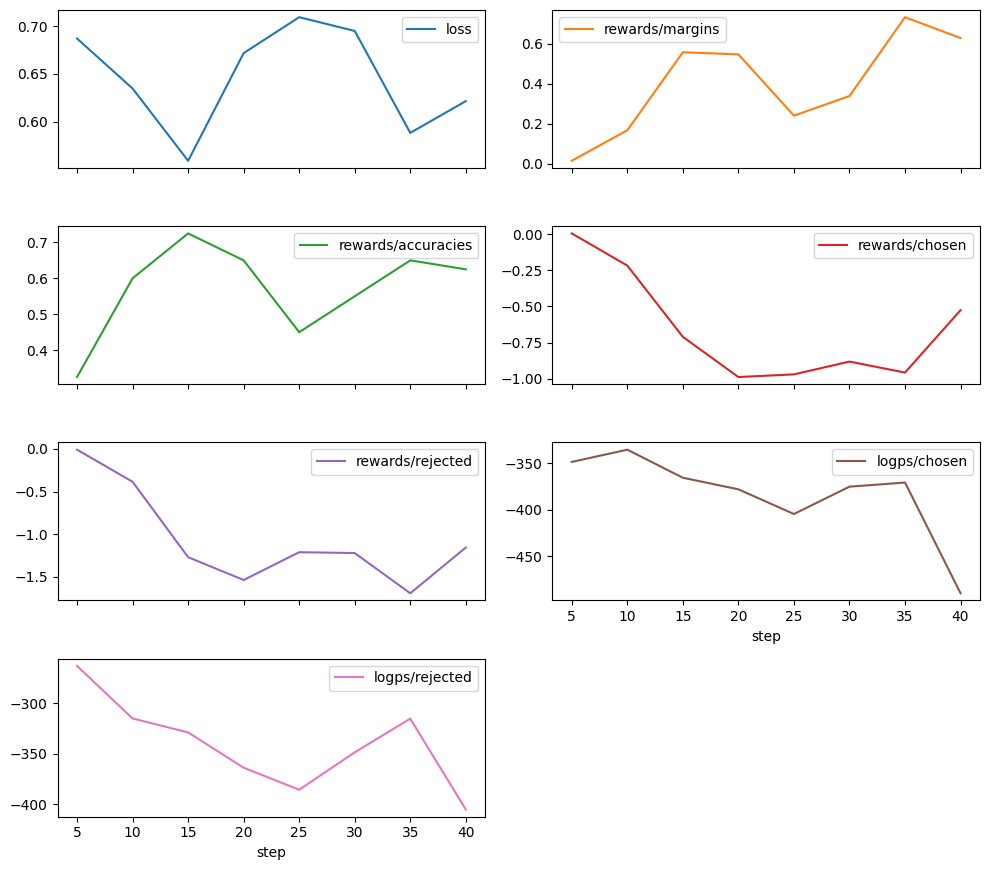

In [24]:
log = pd.DataFrame([h for h in treinador.state.log_history if "loss" in h and "train_runtime" not in h])
cols = [c for c in ["loss", "rewards/margins", "rewards/accuracies", "rewards/chosen", "rewards/rejected", "logps/chosen", "logps/rejected"] if c in log]
log.plot(x="step", y=cols, subplots=True, layout=(-1, 2), figsize=(10, 2.2 * math.ceil(len(cols) / 2)), legend=True); plt.tight_layout(); plt.show()

✍️ **P4.1** Descreva a evolução de `rewards/accuracies` e `rewards/margins`. As recompensas implícitas de *chosen* sobem ou descem? E `logps/chosen`? Interprete.

**✍️ Resposta:** O rewards/accuracies sobe no início, de cerca de 0,32 para 0,72, mas depois é bastante irregular: desce para 0,45 e acaba perto de 0,62. O rewards/margins também sobe no geral (chega a ~0,75), mas com um vale perto de 0,25 a meio. Não é uma subida limpa porque só são 40 passos e lotes pequenos.

As recompensas implícitas descem as duas. A chosen vai de 0 até cerca de -1,0 e recupera para -0,5, e a rejected vai de 0 até cerca de -1,7 e acaba em -1,1. Como a rejected desce mais, a margem aumenta. O logps/chosen desce de -350 para -480 e o logps/rejected de -270 para -400, por isso a probabilidade absoluta desce nos dois; o que melhora é a ordem relativa entre as respostas.

In [25]:
@torch.no_grad()
def gerar(modelo, prompt, max_new_tokens=150):
    ids = tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True, return_tensors="pt").to(modelo.device)
    out = modelo.generate(ids, max_new_tokens=max_new_tokens, do_sample=False)
    return tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True)

m = treinador.model.eval()
for pr in ["Give me three tips to write a good scientific abstract.", "Is it safe to eat raw chicken? Answer briefly."]:
    with m.disable_adapter():
        antes = gerar(m, pr)
    depois = gerar(m, pr)
    print(f"### {pr}\n--- ANTES ({len(antes.split())} palavras)\n{antes}\n--- DEPOIS ({len(depois.split())} palavras)\n{depois}\n")

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(
The attention mask is not set and cannot be inferred from input because pad token is same as eos toke

### Give me three tips to write a good scientific abstract.
--- ANTES (115 palavras)
Certainly! Writing a scientific abstract is crucial for presenting your research effectively and clearly. Here are three key tips to help you create an engaging and informative scientific paper:

1. **Keep it concise**: Scientific papers should be brief but comprehensive. Aim for around 200-300 words per page. This allows readers to quickly grasp the main points of your work without having to read through the entire paper.

2. **Use clear and precise language**: Avoid jargon or overly technical terms unless they are essential to your field of study. Use simple language that is easy for non-specialists to understand. For example, instead of saying "We found [X]," say "We observed [X]."

3. **Provide context and background
--- DEPOIS (126 palavras)
Writing a scientific abstract is crucial for presenting your research effectively and clearly. Here are three key tips to help you create an engaging and info

✍️ **P4.2** Que diferenças observa (estilo, estrutura, comprimento)? Com 40 passos, o que é plausível ter mudado e o que não? Como verificaria se há viés de comprimento?

**✍️ Resposta:** As respostas mudam pouco. Na primeira pergunta passam de 115 para 126 palavras e na segunda de 111 para 113, por isso ficam um pouco mais longas. O estilo também fica mais estruturado e mais polido, e o "Certainly!" do início desaparece. Mas o conteúdo continua parecido: na pergunta do frango cru o modelo continua a dizer que é geralmente seguro comer, o que está errado antes e depois.

Com 40 passos e LoRA o modelo muda sobretudo o estilo, não aprende factos novos. O viés de comprimento é o risco principal, porque no UltraFeedback as respostas chosen são em média mais longas. Para verificar mediria o número de palavras antes e depois nos mesmos prompts e comparava com o comprimento médio das chosen e rejected nos dados. Também podia truncar as respostas ao mesmo tamanho para ver se a preferência se mantinha.

In [26]:
del treinador, modelo, m; gc.collect(); torch.cuda.empty_cache()

## 5 · GRPO com recompensas verificáveis (≈ 20 min, ~8 min de treino)

### 5.1 · Vantagens relativas ao grupo

$$\hat A_i=\frac{r_i-\operatorname{mean}(r)}{\operatorname{std}(r)+\varepsilon}$$

In [27]:
def vantagens_grupo(r, normalizar_std=True, eps=1e-4):
    r = np.asarray(r, dtype=float)
    a = r - r.mean()
    if normalizar_std:
        a = a / (r.std() + eps)
    return a

print(vantagens_grupo([1, 0, 1, 0]).round(3), vantagens_grupo([1, 1, 1, 1]), vantagens_grupo([1, 0, 0, 0]).round(3))
assert np.allclose(vantagens_grupo([1, 0, 1, 0]), [1, -1, 1, -1], atol=1e-3)
assert np.allclose(vantagens_grupo([1, 1, 1, 1]), 0)

[ 1. -1.  1. -1.] [0. 0. 0. 0.] [ 1.732 -0.577 -0.577 -0.577]


✍️ **P5.1** Compare $[1,0,0,0]$ com $[1,1,1,0]$: que resposta recebe a maior vantagem absoluta em cada caso? Porque é que a divisão pelo desvio-padrão cria um viés de dificuldade (Dr. GRPO)?

**✍️ Resposta:** Em [1,0,0,0] a média é 0,25 e o desvio 0,433, por isso a resposta correta fica com vantagem +1,73 e as erradas com -0,58. Em [1,1,1,0] a média é 0,75, a correta fica com +0,58 e a errada com -1,73.

Então no primeiro caso a correta tem a maior vantagem, mas no segundo é a errada que tem a maior vantagem (em módulo). A divisão pelo desvio faz com que grupos quase todos iguais (quase todos certos ou quase todos errados) tenham vantagens maiores, o que dá mais peso a esses prompts. Isto é o viés de dificuldade que o Dr. GRPO tenta resolver, deixando de dividir pelo desvio e pelo comprimento.

### 5.2 · Funções de recompensa

O modelo deve terminar com `Resposta: <número>`. Implemente uma recompensa de **correção** (1,0 ou 0,0) e uma de **formato** (0,2). Na TRL, cada função recebe `completions` (lista de mensagens) e as colunas do dataset como argumentos nomeados.

In [28]:
SISTEMA = "Resolve o problema passo a passo e termina com uma linha no formato 'Resposta: <número>'."
RE_RESP = re.compile(r"Resposta:\s*\$?\s*(-?[\d.,]+)", re.IGNORECASE)

def _texto(c):
    return c[0]["content"] if isinstance(c, list) else c

def extrair_numero(texto):
    m = RE_RESP.findall(texto)
    if not m:
        return None
    try:
        return float(m[-1].replace(",", "").rstrip("."))
    except ValueError:
        return None

def recompensa_correcao(completions, resposta, **kwargs):
    notas = []
    for c, ref in zip(completions, resposta):
        num = extrair_numero(_texto(c))
        try:
            ref = float(str(ref).replace(",", ""))
        except ValueError:
            ref = None
        notas.append(1.0 if num is not None and ref is not None and abs(num - ref) < 1e-6 else 0.0)
    return notas

def recompensa_formato(completions, **kwargs):
    return [0.2 if RE_RESP.search(_texto(c)) else 0.0 for c in completions]

testes = [[{"role": "assistant", "content": "3 + 4 = 7.\nResposta: 7"}],
          [{"role": "assistant", "content": "Acho que é 8.\nResposta: 8."}],
          [{"role": "assistant", "content": "São 1,000 euros. Resposta: $1,000"}],
          [{"role": "assistant", "content": "A resposta é 7."}]]
print(recompensa_correcao(testes, ["7", "7", "1000", "7"]), recompensa_formato(testes))
assert recompensa_correcao(testes, ["7", "7", "1000", "7"]) == [1.0, 0.0, 1.0, 0.0]

[1.0, 0.0, 1.0, 0.0] [0.2, 0.2, 0.2, 0.0]


✍️ **P5.2** Encontre pelo menos **duas** formas de a política obter recompensa sem resolver o problema, ou de ser penalizada injustamente (ex.: decimais com vírgula em português). Como corrigiria?

**✍️ Resposta:** Uma forma de ganhar recompensa sem resolver nada é meter só a linha "Resposta: 42" sem raciocínio nenhum, porque o formato já dá 0,2. Outra é escrever várias linhas "Resposta:" com números diferentes, porque o parser só usa a última, e assim o modelo pode tentar adivinhar várias vezes.

Também há casos em que é penalizado injustamente por causa das vírgulas. Em português "Resposta: 0,5" devia ser 0,5, mas o código faz replace(",", "") e fica 5, então conta como errado. O mesmo acontece com "1,5", que fica 15. A comparação exata também falha com coisas como 0,333 contra 1/3.

Para corrigir fazia um parser de números melhor, que percebesse quando a vírgula é decimal e quando é de milhar, comparasse com uma pequena tolerância e só aceitasse uma linha "Resposta:" no fim.

In [29]:
from trl import GRPOConfig, GRPOTrainer

def preparar(ex):
    return {"prompt": [{"role": "system", "content": SISTEMA}, {"role": "user", "content": ex["question"]}],
            "resposta": ex["answer"].split("####")[-1].strip().replace(",", "")}

gsm = load_dataset("openai/gsm8k", "main")
treino = gsm["train"].shuffle(seed=0).select(range(400)).map(preparar, remove_columns=["question", "answer"])
teste = gsm["test"].shuffle(seed=0).select(range(30)).map(preparar, remove_columns=["question", "answer"])

@torch.no_grad()
def exatidao(modelo, dados, max_new_tokens=256):
    modelo.eval(); acertos, formato = 0, 0
    for ex in dados:
        ids = tok.apply_chat_template(ex["prompt"], add_generation_prompt=True, return_tensors="pt").to(modelo.device)
        out = tok.decode(modelo.generate(ids, max_new_tokens=max_new_tokens, do_sample=False)[0, ids.shape[1]:], skip_special_tokens=True)
        acertos += recompensa_correcao([out], [ex["resposta"]])[0]; formato += recompensa_formato([out])[0] > 0
    return acertos / len(dados), formato / len(dados)

modelo = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32).to(DEVICE)
acc0 = exatidao(modelo, teste); print(f"ANTES — exatidão: {acc0[0]:.0%} | formato: {acc0[1]:.0%}")

README.md: 0.00B [00:00, ?B/s]

main/train-00000-of-00001.parquet:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

main/test-00000-of-00001.parquet:   0%|          | 0.00/419k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/30 [00:00<?, ? examples/s]

ANTES — exatidão: 0% | formato: 10%


In [30]:
cfg_grpo = GRPOConfig(
    output_dir="grpo-qwen05", learning_rate=2e-5, lr_scheduler_type="constant",
    per_device_train_batch_size=8, gradient_accumulation_steps=1, num_generations=4,   # 2 prompts × 4 respostas por passo
    max_prompt_length=256, max_completion_length=256, temperature=1.0,
    beta=0.04, loss_type="grpo", max_steps=40, gradient_checkpointing=True,
    bf16=BF16, fp16=(DEVICE == "cuda" and not BF16),
    logging_steps=5, save_strategy="no", report_to="none",
)
treinador = GRPOTrainer(model=modelo, reward_funcs=[recompensa_correcao, recompensa_formato],
                        args=cfg_grpo, train_dataset=treino, processing_class=tok, peft_config=lora)
treinador.train()

No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.
`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Step,Training Loss
5,0.000300
10,0.001500
15,0.001900
20,0.002300
25,0.001700
30,0.001700
35,0.001600
40,0.002200


TrainOutput(global_step=40, training_loss=0.0016737095080316066, metrics={'train_runtime': 303.5334, 'train_samples_per_second': 1.054, 'train_steps_per_second': 0.132, 'total_flos': 0.0, 'train_loss': 0.0016737095080316066})

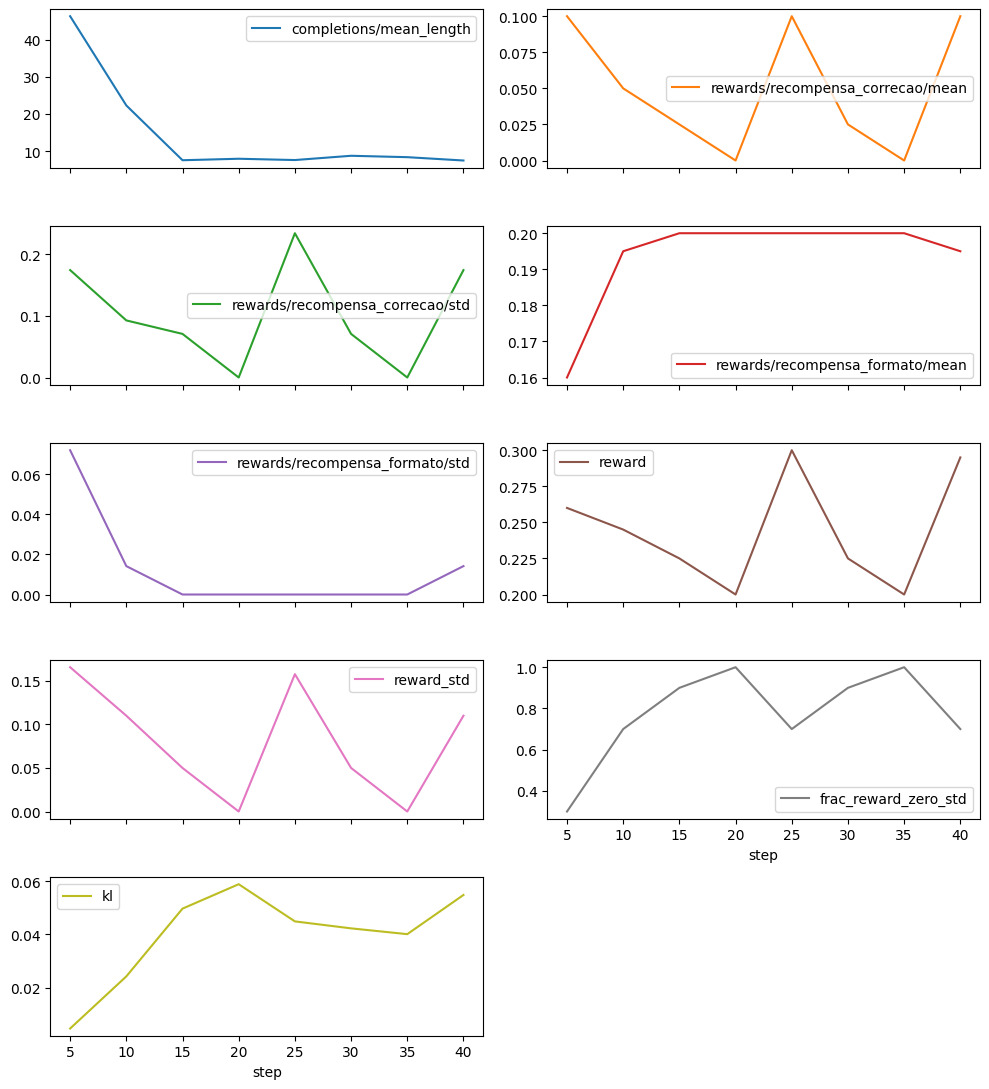

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


ANTES  — exatidão: 0% | formato: 10%
DEPOIS — exatidão: 3% | formato: 100%


In [31]:
log = pd.DataFrame([h for h in treinador.state.log_history if "train_runtime" not in h])
cols = [c for c in log.columns if any(k in c for k in ["reward", "kl", "mean_length", "zero_std", "entropy"]) and log[c].notna().any()]
log.plot(x="step", y=cols, subplots=True, layout=(-1, 2), figsize=(10, 2.2 * math.ceil(len(cols) / 2))); plt.tight_layout(); plt.show()
acc1 = exatidao(treinador.model, teste)
print(f"ANTES  — exatidão: {acc0[0]:.0%} | formato: {acc0[1]:.0%}\nDEPOIS — exatidão: {acc1[0]:.0%} | formato: {acc1[1]:.0%}")

✍️ **P5.3** Interprete as curvas: recompensa média, `reward_std`, fração de grupos com desvio nulo, KL e comprimento. A melhoria (se houver) vem da correção ou do formato? Com 30 exemplos de teste, quão confiável é a diferença?

**✍️ Resposta:** A recompensa média anda à volta de 0,20-0,30 e sobe no fim, mas com muitas oscilações. O reward_std tende a diminuir, de cerca de 0,16 para 0,11, e a fração de grupos com desvio nulo aumenta de 0,3 para 0,73 (chegando a 1,0 a meio). Quando o grupo acerta ou falha todo, a vantagem é 0 e já não se aprende nada. O KL vai crescendo de 0 até cerca de 0,057.

O comprimento médio das respostas desce muito, de ~47 para ~8 tokens, porque o modelo aprende depressa a escrever só a linha "Resposta: ..." e deixa de fazer raciocínio. A recompensa de formato sobe de 0,16 para 0,20, que quer dizer de 80% para 100% das respostas com formato.

A exatidão passa de 0% para 3%, ou seja, acerta 1 exemplo em 30. Isto não é de confiar: o erro-padrão é cerca de 9 pontos percentuais e o intervalo de confiança a 95% fica perto de ±18. A melhoria vem quase toda do formato e não da correção. Para ter a certeza usava o teste completo do GSM8K, que tem 1319 exemplos, e um teste de McNemar.

## 6 · Desafios extra (para quem terminar cedo ou como trabalho de casa)

1. **Dr. GRPO vs GRPO:** repita a Parte 5 com `loss_type="dr_grpo"` e `scale_rewards=False`. Compare o comprimento das respostas.
2. **β = 0:** treine o GRPO sem KL. O que acontece à entropia e ao KL implícito?
3. **IPO:** na Parte 4, use `loss_type="ipo"` no `DPOConfig` e compare `logps/chosen`.
4. **Português:** adapte os filtros da Parte 1 a português (stopwords, comprimento médio) e meça quantos originais deixam de ser removidos.
5. **Hacking:** suba a recompensa de formato para 1,0 e observe se a correção piora.

## 📦 Entrega

Submeta este notebook **executado**, com todas as células ✍️ respondidas, até ao fim da semana. Critérios: código correto (40 %), qualidade das respostas e interpretação dos gráficos (45 %), desafio extra (15 %).